In [3]:
!pip install openpyxl

In [5]:
import pandas as pd
import numpy as np
import os
import glob

data_path = '/Users/azaliavagizova/Desktop/service_bi/data/raw/'

income_files = glob.glob(os.path.join(data_path, 'inc_*.xlsx'))
print(f"Найдено файлов по доходам: {len(income_files)}")

file_to_read = None
for f in income_files:
    if "Динамика денежных доходов" in f:
        file_to_read = f
        break

if file_to_read:
    print(f"Читаем файл: {file_to_read}")
    
    df = pd.read_excel(file_to_read, header=None)
    print("Первые 10 строк файла:")
    display(df.head(10))
else:
    print("Файл с доходами не найден. Проверь путь.")

Найдено файлов по доходам: 20
Читаем файл: /Users/azaliavagizova/Desktop/service_bi/data/raw/inc_6_Динамика денежных доходов населения г. Москвы за 2014-2024 г.xlsx
Первые 10 строк файла:


,0,1,2,3,4,5,6,7,8,9,10,11
0,Динамика денежных доходов населения Москвы1),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Показатели,2.014000e+03,2.015000e+03,2.016000e+03,2.017000e+03,2.018000e+03,2.019000e+03,2.020000e+03,2.021000e+03,2.022000e+03,2.023000e+03,20242)
3,Денежные доходы (тыс.рублей),8.089882e+09,8.908737e+09,9.193008e+09,9.776265e+09,1.053998e+10,1.151728e+10,1.187201e+10,1.348391e+10,1.600750e+10,1.844649e+10,22699017004
4,Потребительские расходы (тыс.рублей),6.995101e+09,7.104709e+09,7.123740e+09,7.625711e+09,8.391132e+09,8.945465e+09,7.984112e+09,9.579692e+09,1.052047e+10,1.229488e+10,14336212094
5,Денежные доходы в расчете на душу на...,5.567049e+04,6.046518e+04,6.164902e+04,6.480502e+04,6.891496e+04,7.447522e+04,7.631980e+04,8.645344e+04,1.021430e+05,1.171030e+05,143171.2
6,Потребительские расходы в расчете н...,4.813676e+04,4.822093e+04,4.777235e+04,5.054941e+04,5.486484e+04,5.784485e+04,5.132624e+04,6.142117e+04,6.713100e+04,7.805100e+04,90423.9
7,"Денежные доходы в расчете \nна душу населения,...",9.917227e+01,1.086126e+02,1.019579e+02,1.051193e+02,1.063420e+02,1.080683e+02,1.024768e+02,1.132779e+02,1.181000e+02,1.146000e+02,122.3
8,Потребительские расходы \nв расчете на душу на...,1.073786e+02,1.001749e+02,9.906974e+01,1.058131e+02,1.085371e+02,1.054315e+02,8.873087e+01,1.196682e+02,1.093000e+02,1.163000e+02,115.9
9,Реальные денежные доходы в % к соответствующем...,9.271641e+01,9.441993e+01,9.571555e+01,1.015126e+02,1.041000e+02,1.046000e+02,1.002000e+02,1.076000e+02,1.051000e+02,1.088000e+02,112.9


Очищенные года: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Количество лет: 10


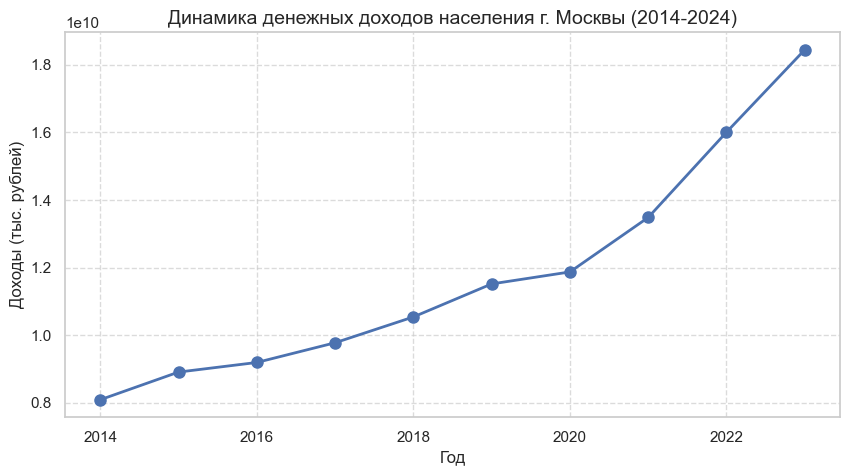

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")

# 1. Берем только те строки, которые нам нужны
# Строка 2 (индекс 2) — это года. Строка 3 (индекс 3) — Денежные доходы (тыс. рублей).
raw_years = df.iloc[2, 1:].values          
raw_incomes = df.iloc[3, 1:].values        

# 2. Очищаем данные от мусора (скобок, сносок, пустых строк)
years_clean = []
incomes_clean = []

for y, i in zip(raw_years, raw_incomes):
    y_str = str(y).strip()
    i_str = str(i).strip()
    
    # Берем только те года, которые можно превратить в число (2014, 2015...)
    try:
        year_num = int(float(y_str))
        # Если в строке с доходом есть цифры, тоже берем
        if i_str != 'nan' and i_str != '':
            income_num = float(i_str)
            
            # Добавляем в чистые списки
            years_clean.append(year_num)
            incomes_clean.append(income_num)
    except ValueError:
        # Если не получилось превратить в число (например, вылезла скобка), просто пропускаем
        continue

print(f"Очищенные года: {years_clean}")
print(f"Количество лет: {len(years_clean)}")

# 3. Строим график
plt.figure(figsize=(10, 5)) # Размер графика
plt.plot(years_clean, incomes_clean, marker='o', color='b', linewidth=2, markersize=8)

# Добавляем подписи
plt.title('Динамика денежных доходов населения г. Москвы (2014-2024)', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Доходы (тыс. рублей)', fontsize=12)

# Включаем сетку
plt.grid(True, linestyle='--', alpha=0.7)

# Показываем график
plt.show()

In [11]:
# Загружаем файл с бедностью
file_poverty = os.path.join(data_path, 'inc_14_Доля населения с денежными доходами ниже прожиточного миниму.xlsx')
df_poverty = pd.read_excel(file_poverty, header=None)

# Выведем первые 10 строк, чтобы посмотреть, как там устроены данные
display(df_poverty.head(10))

,0,1
0,Уровень бедности по г. Москве за 2011-2025 гг.,NaN
1,NaN,NaN
2,Годы,В процентах от общей численности населения г. ...
3,2011,10
4,2012,9.4
5,2013,8.7
6,2014,8.8
7,2015,8.9
8,2016,8.5
9,2017,7.6


Года: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Уровень бедности (%): [10.0, 9.4, 8.7, 8.8, 8.9, 8.5, 7.6, 6.7, 6.5, 6.1, 5.7, 4.8, 4.4, 4.0]


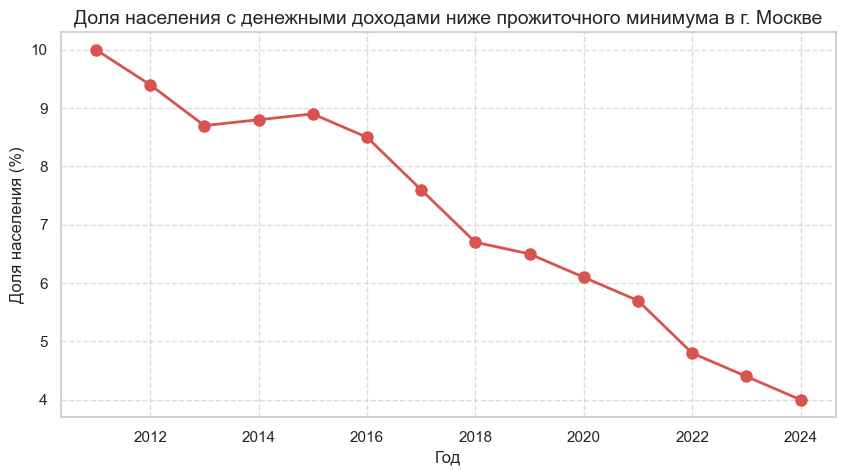

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Берем данные, начиная с 3-й строки (индекс 3), так как первые строки — это заголовки
# Столбец 0 — года, Столбец 1 — проценты
raw_years = df_poverty.iloc[3:, 0].values
raw_values = df_poverty.iloc[3:, 1].values

years_clean = []
values_clean = []

for y, v in zip(raw_years, raw_values):
    try:
        # Превращаем в числа
        year_num = int(float(str(y).strip()))
        val_num = float(str(v).strip())
        
        years_clean.append(year_num)
        values_clean.append(val_num)
    except ValueError:
        # Пропускаем строки с мусором
        continue

print(f"Года: {years_clean}")
print(f"Уровень бедности (%): {values_clean}")

# Строим график
plt.figure(figsize=(10, 5))
# Используем красный цвет, так как бедность — это отрицательный показатель
plt.plot(years_clean, values_clean, marker='o', color='#d9534f', linewidth=2, markersize=8)

plt.title('Доля населения с денежными доходами ниже прожиточного минимума в г. Москве', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Доля населения (%)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [15]:
# Ищем файл с заболеваемостью
health_files = glob.glob(os.path.join(data_path, 'health_*.xlsx'))
file_morbidity = None
for f in health_files:
    if "Заболеваемость" in f:
        file_morbidity = f
        break

if file_morbidity:
    print(f"Читаем файл: {file_morbidity}")
    # Открываем файл (берем первый лист)
    df_morb = pd.read_excel(file_morbidity, header=None)
    print("Первые 15 строк:")
    display(df_morb.head(15))
else:
    print("Файл с заболеваемостью не найден.")

Читаем файл: /Users/azaliavagizova/Desktop/service_bi/data/raw/health_3_Заболеваемость населения по основным классам болезней в 2020.xlsx
Первые 15 строк:


,0,1,2,3,4,5
0,Заболеваемость населения по основным классам б...,NaN,NaN,NaN,NaN,NaN
1,(Данные Департамента здравоохранения г. Москвы...,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,2020.0,2021.0,2022.0,2023.0,2024
4,"Всего, человек",NaN,NaN,NaN,NaN,NaN
5,Все болезни,8013110.0,9051391.0,9514695.0,9105019.0,8905373
6,из них:,NaN,NaN,NaN,NaN,NaN
7,некоторые инфекционные и паразитарные болезни,219462.0,236332.0,259008.0,280312.0,284789
8,новообразования,121483.0,139645.0,151695.0,175671.0,196220
9,"болезни крови, кроветворных органов \nи отдель...",10427.0,12884.0,13541.0,13618.0,15882


Обработано болезней: 17


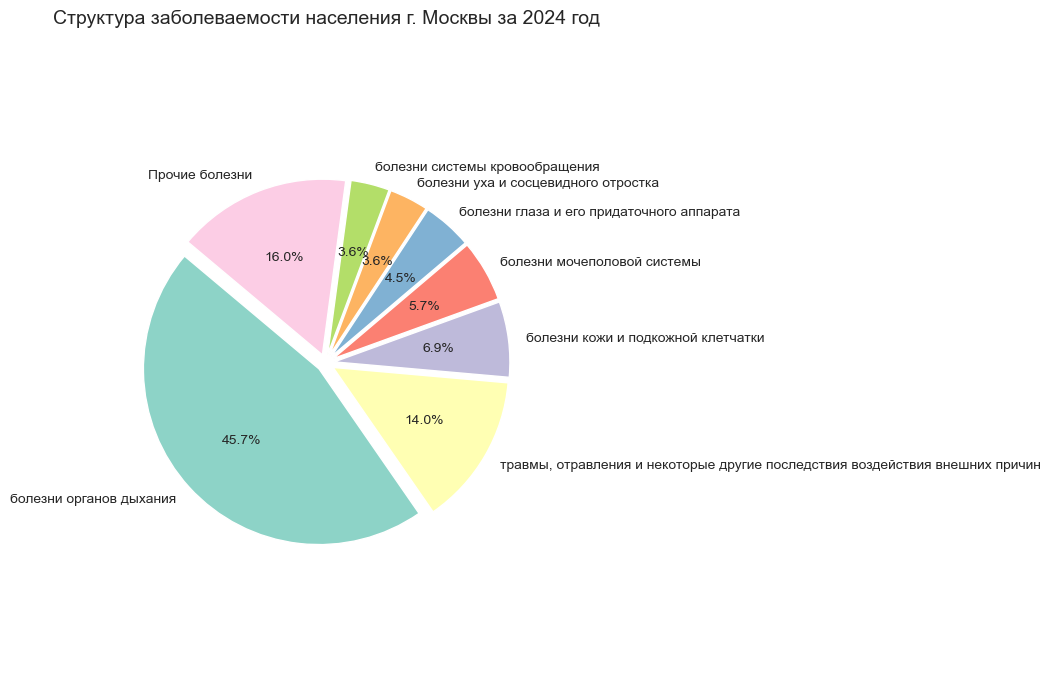

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Достаем названия болезней и данные за 2024 год (столбец с индексом 5)
# Берем строки с 7 по 25
diseases_raw = df_morb.iloc[7:25, 0].values
cases_2024 = df_morb.iloc[7:25, 5].values

diseases = []
cases = []

for d, c in zip(diseases_raw, cases_2024):
    d_str = str(d).strip()
    c_str = str(c).strip()
    
    # Пропускаем пустые строки и мусор
    if d_str != 'nan' and d_str != '':
        try:
            # Пытаемся превратить в число. Если там прочерк, вылезет ошибка, и мы пропустим строку
            case_num = float(c_str)
            if not np.isnan(case_num) and case_num > 0:
                diseases.append(d_str)
                cases.append(case_num)
        except ValueError:
            continue

print(f"Обработано болезней: {len(diseases)}")

# Сортируем по убыванию
sorted_data = sorted(zip(diseases, cases), key=lambda x: x[1], reverse=True)

# Берем ТОП-7
top_7 = sorted_data[:7]
other_cases = sum([x[1] for x in sorted_data[7:]])

labels = [x[0] for x in top_7] + ['Прочие болезни']
sizes = [x[1] for x in top_7] + [other_cases]

# 2. Строим круговую диаграмму
plt.figure(figsize=(10, 7))
colors = plt.cm.Set3.colors

# Добавляем explode для красоты (сдвигаем "Прочие")
explode = tuple([0.05] * len(sizes)) 

plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=False, startangle=140, textprops={'fontsize': 10})

plt.title('Структура заболеваемости населения г. Москвы за 2024 год', fontsize=14, pad=20)
plt.axis('equal')
plt.tight_layout()

plt.show()

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Ищем файл с медицинскими кадрами
file_staff = None
for f in health_files:
    if "кадр" in f.lower():
        file_staff = f
        break

if file_staff:
    print(f"Читаем файл: {file_staff}")
    df_staff = pd.read_excel(file_staff, header=None)
    
    # Выведем первые 10 строк, чтобы посмотреть структуру
    display(df_staff.head(10))
else:
    print("Файл с медицинскими кадрами не найден.")

Читаем файл: /Users/azaliavagizova/Desktop/service_bi/data/raw/health_21_Численность медицинских кадров за 2012-2020 гг..xlsx


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,Численность медицинских кадров,NaN,NaN,NaN,NaN
2,(на конец года),NaN,NaN,NaN,NaN
3,город Москва,NaN,NaN,NaN,NaN
4,Годы,Численность врачей,NaN,Численность среднего,NaN
5,NaN,NaN,NaN,медицинского персонала,NaN
6,NaN,"всего, человек",на 10 000 человек,"всего, человек",на 10 000 человек
7,NaN,NaN,населения,NaN,населения
8,2012 1),82595,68.9,115567,96.5
9,2013,83116,68.6,118529,97.9


Года: [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]


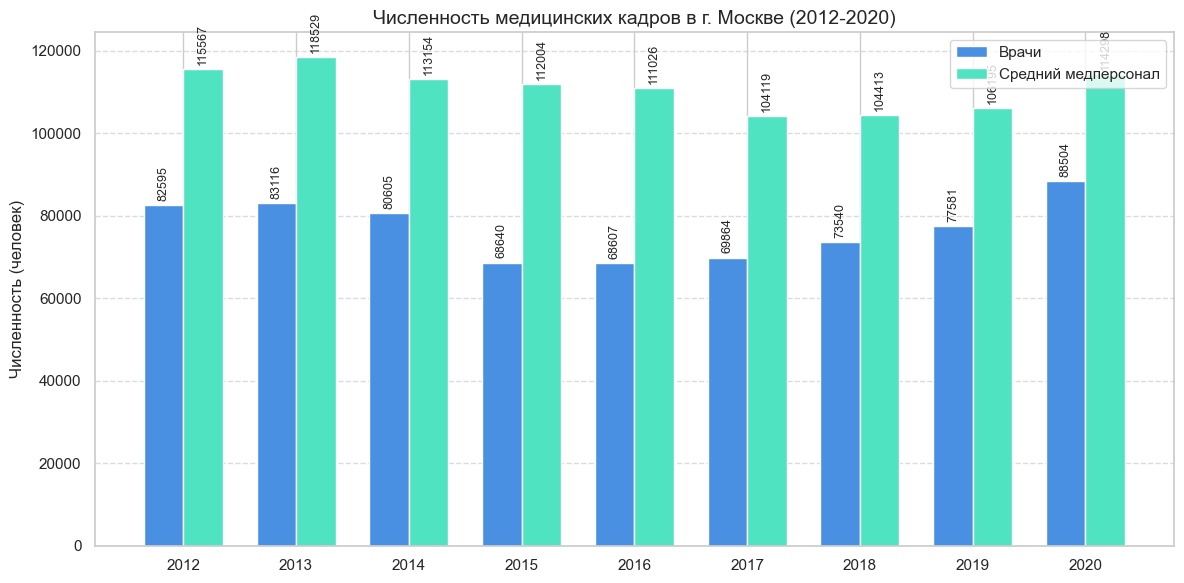

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Достаем данные, начиная с 8-й строки (индекс 8)
raw_years = df_staff.iloc[8:, 0].values
raw_doctors = df_staff.iloc[8:, 1].values
raw_nurses = df_staff.iloc[8:, 3].values

years_clean = []
doctors_clean = []
nurses_clean = []

for y, d, n in zip(raw_years, raw_doctors, raw_nurses):
    y_str = str(y).strip()
    d_str = str(d).strip()
    n_str = str(n).strip()
    
    # Проверяем, что данные не пустые
    if y_str != 'nan' and d_str != 'nan':
        try:
            # Очищаем год от скобок и лишних символов (например, "2012 1)" -> 2012)
            year_num = int(float(y_str.split()[0]))
            doc_num = float(d_str)
            nur_num = float(n_str)
            
            years_clean.append(year_num)
            doctors_clean.append(doc_num)
            nurses_clean.append(nur_num)
        except ValueError:
            continue

print(f"Года: {years_clean}")

# 2. Строим столбчатую диаграмму
x = np.arange(len(years_clean))  # Позиции по оси X
width = 0.35  # Ширина столбцов

fig, ax = plt.subplots(figsize=(12, 6))

# Рисуем столбцы для врачей и медсестер
rects1 = ax.bar(x - width/2, doctors_clean, width, label='Врачи', color='#4a90e2')
rects2 = ax.bar(x + width/2, nurses_clean, width, label='Средний медперсонал', color='#50e3c2')

# Подписываем оси
ax.set_ylabel('Численность (человек)', fontsize=12)
ax.set_title('Численность медицинских кадров в г. Москве (2012-2020)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(years_clean)
ax.legend()

# Добавляем значения над столбцами для наглядности
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{int(height)}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, rotation=90)

autolabel(rects1)
autolabel(rects2)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()